In [1]:
import pandas as pd
import matplotlib.pyplot as plt
df = pd.read_csv("sales_clean.csv")
print(df.shape)
df.head()

(292, 7)


,order_id,date,product,price,qty,zip,is_return
0,1254,2026-04-06,mug,11.36,4,60614,False
1,1057,2026-05-30,charger,14.79,3,30303,False
2,1150,2026-05-06,mug,5.50,1,10001,False
3,1066,2026-05-30,notebook,37.53,1,98101,False
4,1114,2026-04-06,webcam,45.59,4,90405,False


I used my own sales_clean.csv from Lab 3. Its shape is (292, 7) instead of (292, 6) because I added the is_return column in Lab 3.

Center and spread

In [2]:
print("price mean:", df["price"].mean())
print("price median:", df["price"].median())
print("price std:", df["price"].std())
print("qty mean:", df["qty"].mean())
print("qty median:", df["qty"].median())
print("qty std:", df["qty"].std())

price mean: 55.52315068493151
price median: 37.53
price std: 71.76708493504132
qty mean: 2.910958904109589
qty median: 3.0
qty std: 1.559457271336151


I would report the median for price. The mean (55.52) is much higher than the median (37.53), which means a few expensive items pull the mean up. The median is a better description of a typical price.

Histogram of price

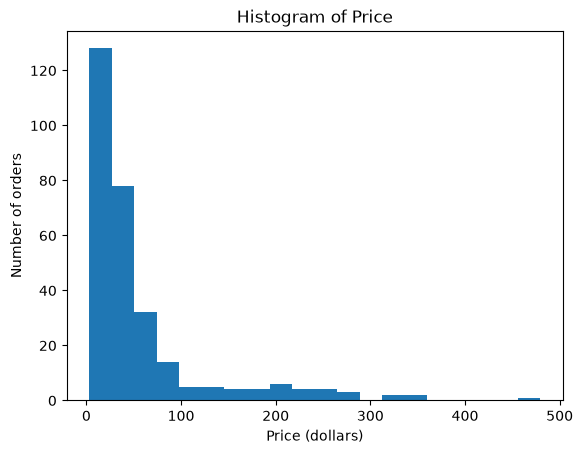

In [3]:
df["price"].plot(kind="hist", bins=20)
plt.title("Histogram of Price")
plt.xlabel("Price (dollars)")
plt.ylabel("Number of orders")
plt.show()

The shape is right skewed: most prices are low and there is a tail of expensive items. This agrees with choosing the median.

Revenue column

In [4]:
df["revenue"] = df["price"] * df["qty"]
df.head()

,order_id,date,product,price,qty,zip,is_return,revenue
0,1254,2026-04-06,mug,11.36,4,60614,False,45.44
1,1057,2026-05-30,charger,14.79,3,30303,False,44.37
2,1150,2026-05-06,mug,5.50,1,10001,False,5.50
3,1066,2026-05-30,notebook,37.53,1,98101,False,37.53
4,1114,2026-04-06,webcam,45.59,4,90405,False,182.36


Correlation matrix

In [5]:
df.corr(numeric_only=True).round(3)

,order_id,price,qty,zip,is_return,revenue
order_id,1.000,-0.005,0.024,-0.015,-0.016,0.006
price,-0.005,1.000,-0.024,0.024,-0.027,0.818
qty,0.024,-0.024,1.000,0.075,-0.430,0.334
zip,-0.015,0.024,0.075,1.000,-0.023,0.045
is_return,-0.016,-0.027,-0.430,-0.023,1.000,-0.123
revenue,0.006,0.818,0.334,0.045,-0.123,1.000


The strongest pair is price and revenue, with r = 0.818. Qty and revenue is weaker at r = 0.334. The other columns (order_id and zip) are just labels, so their correlations are not meaningful.

Scatter plots

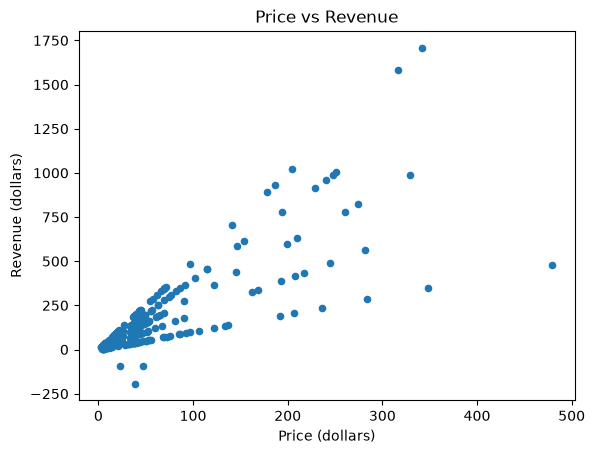

In [6]:
df.plot.scatter(x="price", y="revenue")
plt.title("Price vs Revenue")
plt.xlabel("Price (dollars)")
plt.ylabel("Revenue (dollars)")
plt.show()

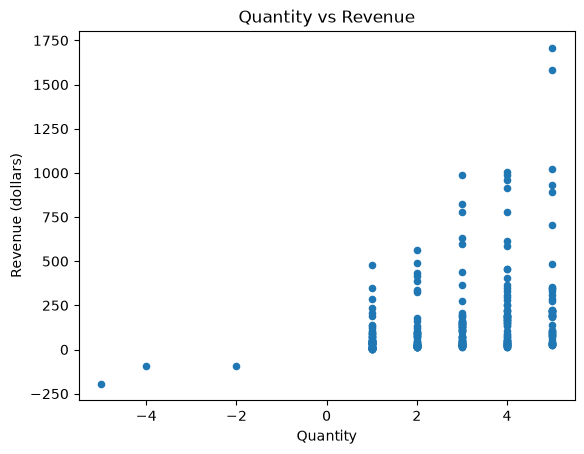

In [7]:
df.plot.scatter(x="qty", y="revenue")
plt.title("Quantity vs Revenue")
plt.xlabel("Quantity")
plt.ylabel("Revenue (dollars)")
plt.show()

The price vs revenue cloud drifts upward clearly, which agrees with r = 0.818. The qty vs revenue cloud is much fuzzier and only rises a little, which agrees with r = 0.334.

Analyst sentence: Orders with a higher unit price tend to bring in much more revenue (r = 0.82), but this is partly built in because revenue is calculated from price, and a few very expensive items could be driving the result.

By hand check

Numbers: 2, 4, 4, 6, 9

Mean = (2 + 4 + 4 + 6 + 9) / 5 = 25 / 5 = 5.0

Median = the middle number of the sorted list 2, 4, 4, 6, 9, which is 4

Now check with Python:

In [8]:
numbers = pd.Series([2, 4, 4, 6, 9])
print(numbers.mean())
print(numbers.median())

5.0
4.0


Repo URL: https://github.com/harveyvasquez/cs82a-portfolio

AI use: Claude helped write the code for labels and scatterplot.